###  A notebook to see how some hyperparameters effect the image

In [ ]:
import nibabel as nib
import nibabel.processing as nibproc
import matplotlib.pyplot as plt
from pathlib import Path
from elasticdeform import deform_random_grid, deform_grid
import numpy as np
from PIL import Image

# Load one patient's CT and ground truth
patient_id = "Patient_03"
source_path = Path("data/segthor_full")

ct_path = source_path / "train" / patient_id / f"{patient_id}.nii.gz"
gt_path = source_path / "train" / patient_id / "GT.nii.gz"

ct_nib = nib.load(str(ct_path))
gt_nib = nib.load(str(gt_path))

ct = np.asarray(ct_nib.dataobj).astype(np.float32)
gt = np.asarray(gt_nib.dataobj).astype(np.uint8)

# Clip HU range
ct = np.clip(ct, -1000, 1000)
ct_nib = nib.Nifti1Image(ct, affine=ct_nib.affine, header=ct_nib.header)

print(f"Before resampling — CT shape: {ct.shape}, GT shape: {gt.shape}")

# B-SPLINE RESAMPLING
new_spacing = (1.0, 1.0, 1.0)

ct_resampled_nib = nibproc.resample_to_output(ct_nib, voxel_sizes=new_spacing, order=3, mode='nearest')
gt_resampled_nib = nibproc.resample_from_to(gt_nib, ct_resampled_nib, order=0, mode='nearest')

ct = np.asarray(ct_resampled_nib.dataobj)
gt = np.asarray(gt_resampled_nib.dataobj).astype(np.uint8)

# Same flip as in slice_patient
ct = np.flip(ct, axis=(0, 1))
gt = np.flip(gt, axis=(0, 1))

print(f"After resampling — CT shape: {ct.shape}, GT shape: {gt.shape}")

Before resampling — CT shape: (512, 512, 147), GT shape: (512, 512, 147)
After resampling — CT shape: (501, 501, 366), GT shape: (501, 501, 366)


In [ ]:
# ELASTIC DEFORMATION
[ct_deformed, gt_deformed] = deform_random_grid(
    [ct, gt],
    sigma=7.5,
    points=2,
    order=[3, 0],
    axis=(0, 1, 2),
)

print(f"Number of differing pixels (full volume): {np.sum(gt != gt_deformed)}")

# Optional: clip HU range, consistent with your preprocessing
ct = np.clip(ct, -1000, 1000)

print(f"CT shape: {ct.shape}, GT shape: {gt.shape}")

Number of differing pixels (full volume): 219957
CT shape: (501, 501, 357), GT shape: (501, 501, 357)


In [2]:
print(ct_nib.header.get_zooms())

(np.float32(0.976562), np.float32(0.976562), np.float32(2.5))


In [4]:
elastic_points = 2

# Quick verification: deform with only z allowed, x/y zeroed, and confirm no change appears in-plane
test_displacement = np.zeros((3, elastic_points, elastic_points, elastic_points))
test_displacement[2] = np.random.randn(elastic_points, elastic_points, elastic_points) * 10  # big z-only displacement

ct_test, gt_test = deform_grid([ct, gt], test_displacement, order=[3, 0], axis=(0,1,2))

# If z-only displacement is correctly applied, a single in-plane slice should look identical
# because deformation should only shift content between slices, not within them
print(np.array_equal(ct[:,:,100], ct_test[:,:,100]))  # likely False, since z-shift changes which slice's content appears at index 100

False


In [5]:
test_displacement = np.zeros((3, elastic_points, elastic_points, elastic_points))
test_displacement[2] = np.random.randn(elastic_points, elastic_points, elastic_points) * 10

print("X displacement (should be all zero):", np.all(test_displacement[0] == 0))
print("Y displacement (should be all zero):", np.all(test_displacement[1] == 0))
print("Z displacement (should be nonzero):", np.any(test_displacement[2] != 0))

X displacement (should be all zero): True
Y displacement (should be all zero): True
Z displacement (should be nonzero): True


# Check deformation from code

Visualize the elastic deformations


In [2]:
base_dir = Path("data/SEGTHOR_elastic_Vnet/train")
img_dir = base_dir / "img"
gt_dir = base_dir / "gt"

patient_id = "Patient_05"

# Find which augmented versions actually exist for this patient
augmented_files = sorted(img_dir.glob(f"{patient_id}_*_*.npy"))  # anything with an extra tag after the slice index
print(f"Found {len(augmented_files)} augmented slices for {patient_id}")
for f in augmented_files[:10]:
    print(f.name)

if not augmented_files:
    raise FileNotFoundError(f"No augmented slices found for {patient_id} — check your naming pattern or that generation actually ran.")

# Pick one augmented slice and find its matching original
example_aug_path = augmented_files[len(augmented_files) // 2]  # grab one from the middle

# Extract the slice index and tag from the filename
# e.g. "Patient_07_0055_elastic_noise.npy" -> stem parts
stem = example_aug_path.stem  # "Patient_02_0055_elastic_noise"
parts = stem.split("_")
# id_ is "Patient_07" (first two parts), idz is parts[2], tag is whatever comes after
idz_str = parts[2]
tag = "_".join(parts[3:])

original_path = img_dir / f"{patient_id}_{idz_str}.npy"
original_gt_path = gt_dir / f"{patient_id}_{idz_str}.png"
aug_gt_path = gt_dir / f"{stem}.png"

print(f"\nComparing:")
print(f"  Original: {original_path.name}")
print(f"  Augmented ({tag}): {example_aug_path.name}")

assert original_path.exists(), f"Missing original slice: {original_path}"


Found 567 augmented slices for Patient_05
Patient_05_0000_elastic.npy
Patient_05_0001_elastic.npy
Patient_05_0002_elastic.npy
Patient_05_0003_elastic.npy
Patient_05_0004_elastic.npy
Patient_05_0005_elastic.npy
Patient_05_0006_elastic.npy
Patient_05_0007_elastic.npy
Patient_05_0008_elastic.npy
Patient_05_0009_elastic.npy

Comparing:
  Original: Patient_05_0283.npy
  Augmented (elastic): Patient_05_0283_elastic.npy


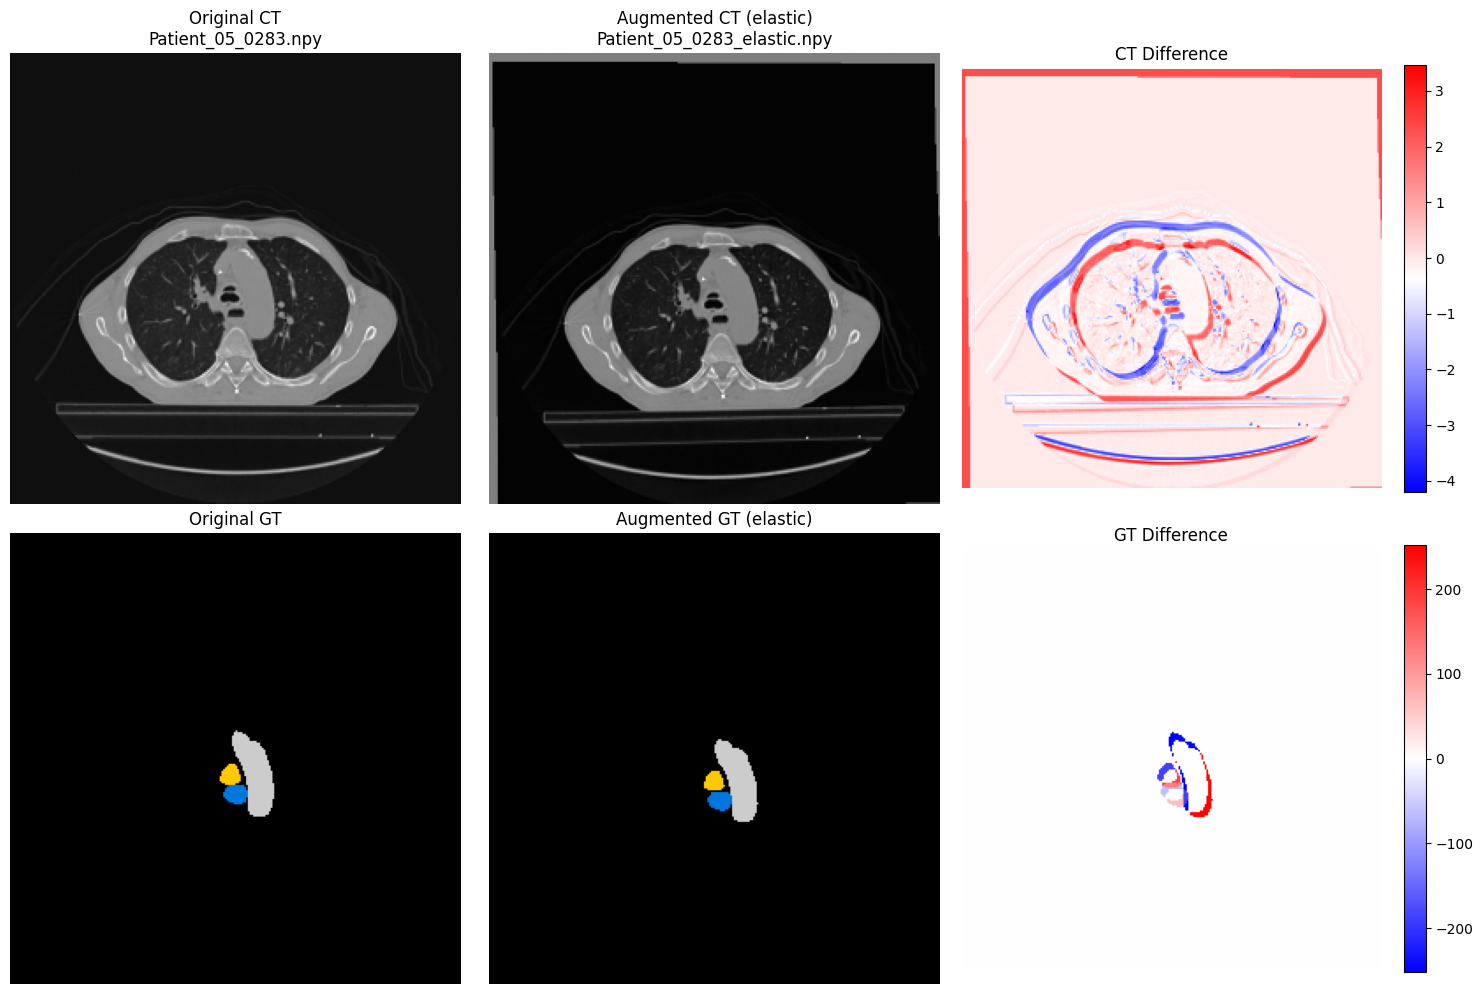


Total abs CT difference: 22818.45, max diff: 4.1998
GT differing pixels: 412
Unique GT values - original: [  0  63 189 252], augmented: [  0  63 189 252]


In [ ]:
orig_img = np.load(original_path)
aug_img = np.load(example_aug_path)

orig_gt = np.array(Image.open(original_gt_path))
aug_gt = np.array(Image.open(aug_gt_path)) if aug_gt_path.exists() else None

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# vmin, vmax = orig_img.min(), orig_img.max()  # consistent scale across both images

axes[0, 0].imshow(orig_img, cmap='gray')
axes[0, 0].set_title(f"Original CT\n{original_path.name}")
axes[0, 0].axis('off')

axes[0, 1].imshow(aug_img, cmap='gray')
axes[0, 1].set_title(f"Augmented CT ({tag})\n{example_aug_path.name}")
axes[0, 1].axis('off')

diff = aug_img - orig_img
im1 = axes[0, 2].imshow(diff, cmap='bwr')
axes[0, 2].set_title("CT Difference")
axes[0, 2].axis('off')
plt.colorbar(im1, ax=axes[0, 2], fraction=0.046)

axes[1, 0].imshow(orig_gt, cmap='nipy_spectral')
axes[1, 0].set_title("Original GT")
axes[1, 0].axis('off')

if aug_gt is not None:
    axes[1, 1].imshow(aug_gt, cmap='nipy_spectral')
    axes[1, 1].set_title(f"Augmented GT ({tag})")
    axes[1, 1].axis('off')

    gt_diff = aug_gt.astype(int) - orig_gt.astype(int)
    im2 = axes[1, 2].imshow(gt_diff, cmap='bwr',)
    axes[1, 2].set_title("GT Difference")
    axes[1, 2].axis('off')
    plt.colorbar(im2, ax=axes[1, 2], fraction=0.046)
else:
    axes[1, 1].axis('off')
    axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

print(f"\nTotal abs CT difference: {np.abs(diff).sum():.2f}, max diff: {np.abs(diff).max():.4f}")
if aug_gt is not None:
    print(f"GT differing pixels: {np.sum(orig_gt != aug_gt)}")
    print(f"Unique GT values - original: {np.unique(orig_gt)}, augmented: {np.unique(aug_gt)}")

### Scaling the difference map with vmin and vmax

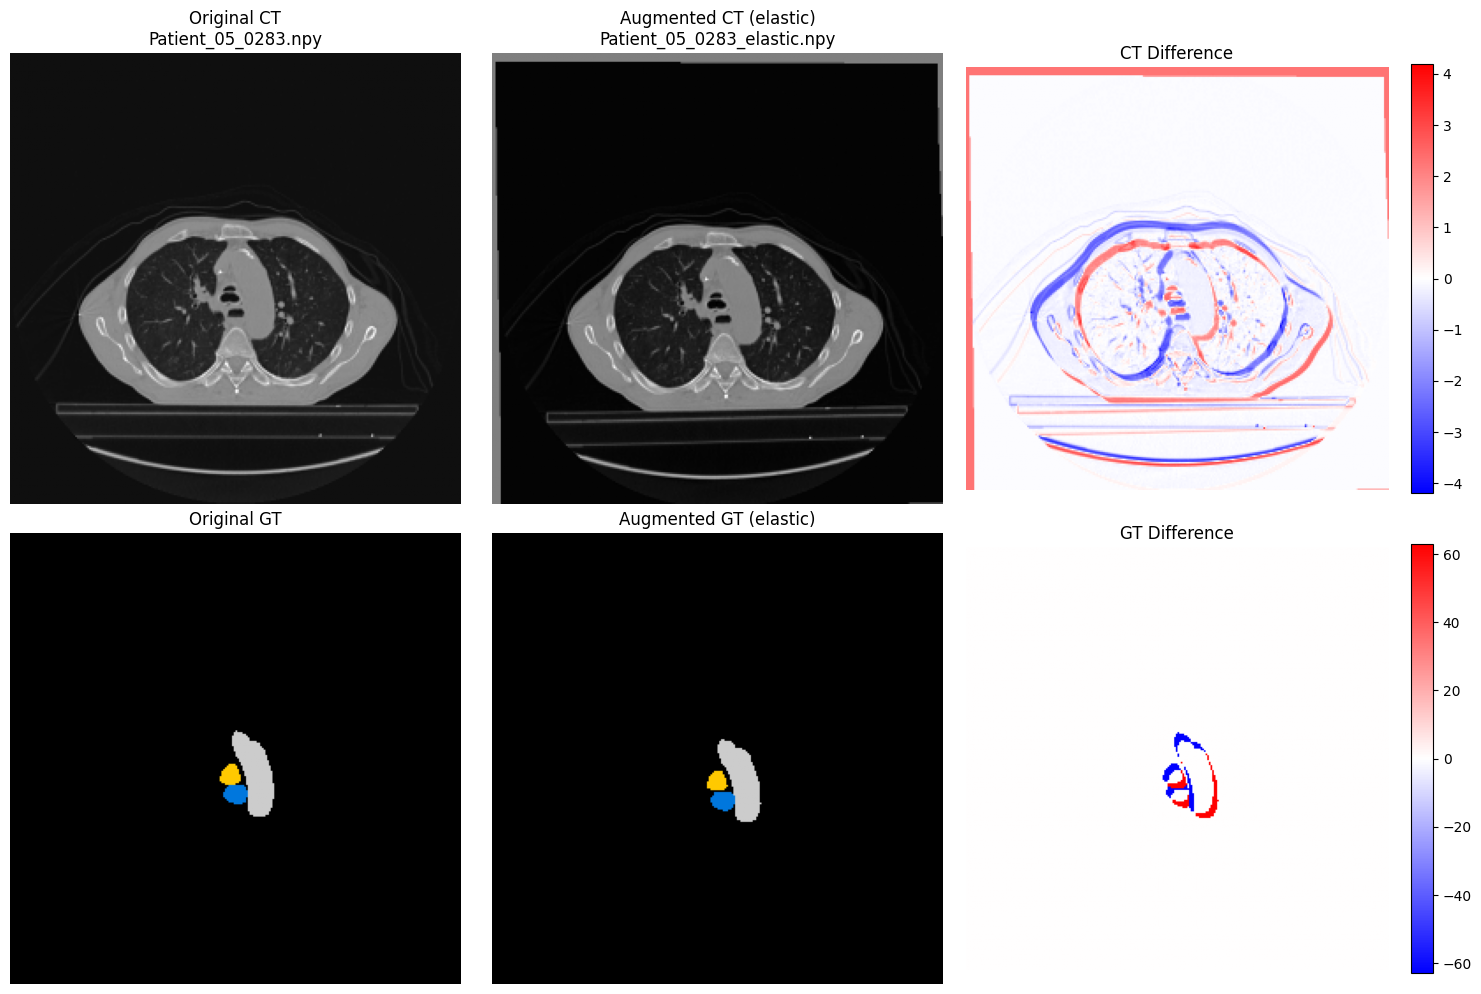


Total abs CT difference: 22818.45, max diff: 4.1998
GT differing pixels: 412
Unique GT values - original: [  0  63 189 252], augmented: [  0  63 189 252]


In [ ]:
orig_img = np.load(original_path)
aug_img = np.load(example_aug_path)

orig_gt = np.array(Image.open(original_gt_path))
aug_gt = np.array(Image.open(aug_gt_path)) if aug_gt_path.exists() else None

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

vmin, vmax = orig_img.min(), orig_img.max()  # consistent scale across both images

axes[0, 0].imshow(orig_img, cmap='gray')
axes[0, 0].set_title(f"Original CT\n{original_path.name}")
axes[0, 0].axis('off')

axes[0, 1].imshow(aug_img, cmap='gray')
axes[0, 1].set_title(f"Augmented CT ({tag})\n{example_aug_path.name}")
axes[0, 1].axis('off')

diff = aug_img - orig_img
im1 = axes[0, 2].imshow(diff, cmap='bwr', vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
axes[0, 2].set_title("CT Difference")
axes[0, 2].axis('off')
plt.colorbar(im1, ax=axes[0, 2], fraction=0.046)

axes[1, 0].imshow(orig_gt, cmap='nipy_spectral', vmin=0, vmax=252)
axes[1, 0].set_title("Original GT")
axes[1, 0].axis('off')

if aug_gt is not None:
    axes[1, 1].imshow(aug_gt, cmap='nipy_spectral', vmin=0, vmax=252)
    axes[1, 1].set_title(f"Augmented GT ({tag})")
    axes[1, 1].axis('off')

    gt_diff = aug_gt.astype(int) - orig_gt.astype(int)
    im2 = axes[1, 2].imshow(gt_diff, cmap='bwr', vmin=-63, vmax=63)
    axes[1, 2].set_title("GT Difference")
    axes[1, 2].axis('off')
    plt.colorbar(im2, ax=axes[1, 2], fraction=0.046)
else:
    axes[1, 1].axis('off')
    axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

print(f"\nTotal abs CT difference: {np.abs(diff).sum():.2f}, max diff: {np.abs(diff).max():.4f}")
if aug_gt is not None:
    print(f"GT differing pixels: {np.sum(orig_gt != aug_gt)}")
    print(f"Unique GT values - original: {np.unique(orig_gt)}, augmented: {np.unique(aug_gt)}")

# Check noise from code

Visualize the Gaussian noise images

In [ ]:
base_dir = Path("data/SEGTHOR_gaussian/train")
img_dir = base_dir / "img"
gt_dir = base_dir / "gt"

patient_id = "Patient_06"

# Find which augmented versions actually exist for this patient
augmented_files = sorted(img_dir.glob(f"{patient_id}_*_*.npy"))  # anything with an extra tag after the slice index
print(f"Found {len(augmented_files)} augmented slices for {patient_id}")
for f in augmented_files[:10]:
    print(f.name)

if not augmented_files:
    raise FileNotFoundError(f"No augmented slices found for {patient_id} — check your naming pattern or that generation actually ran.")

# Pick one augmented slice and find its matching original
example_aug_path = augmented_files[len(augmented_files) // 2]  # grab one from the middle

# Extract the slice index and tag from the filename
# e.g. "Patient_07_0055_elastic_noise.npy" -> stem parts
stem = example_aug_path.stem  # "Patient_02_0055_elastic_noise"
parts = stem.split("_")
# id_ is "Patient_07" (first two parts), idz is parts[2], tag is whatever comes after
idz_str = parts[2]
tag = "_".join(parts[3:])

original_path = img_dir / f"{patient_id}_{idz_str}.npy"
original_gt_path = gt_dir / f"{patient_id}_{idz_str}.png"
aug_gt_path = gt_dir / f"{stem}.png"

print(f"\nComparing:")
print(f"  Original: {original_path.name}")
print(f"  Augmented ({tag}): {example_aug_path.name}")

assert original_path.exists(), f"Missing original slice: {original_path}"


Found 496 augmented slices for Patient_06
Patient_06_0000_noise.npy
Patient_06_0001_noise.npy
Patient_06_0002_noise.npy
Patient_06_0003_noise.npy
Patient_06_0004_noise.npy
Patient_06_0005_noise.npy
Patient_06_0006_noise.npy
Patient_06_0007_noise.npy
Patient_06_0008_noise.npy
Patient_06_0009_noise.npy

Comparing:
  Original: Patient_06_0248.npy
  Augmented (noise): Patient_06_0248_noise.npy


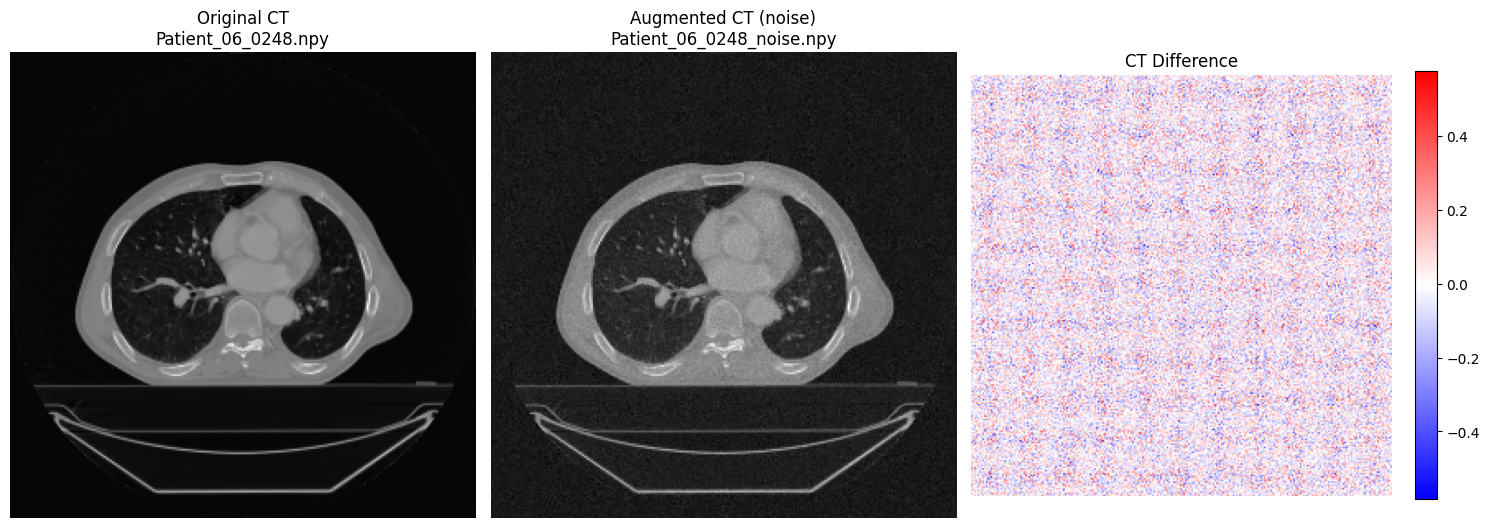


Total abs CT difference: 6173.77, max diff: 0.5842


In [ ]:
orig_img = np.load(original_path)
aug_img = np.load(example_aug_path)

orig_gt = np.array(Image.open(original_gt_path))
aug_gt = np.array(Image.open(aug_gt_path)) if aug_gt_path.exists() else None

fig, axes = plt.subplots(1, 3, figsize=(15, 10))

axes[0].imshow(orig_img, cmap='gray')
axes[0].set_title(f"Original CT\n{original_path.name}")
axes[0].axis('off')

axes[1].imshow(aug_img, cmap='gray')
axes[1].set_title(f"Augmented CT ({tag})\n{example_aug_path.name}")
axes[1].axis('off')

diff = aug_img - orig_img
im1 = axes[2].imshow(diff, cmap='bwr')
axes[2].set_title("CT Difference")
axes[2].axis('off')
plt.colorbar(im1, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print(f"\nTotal abs CT difference: {np.abs(diff).sum():.2f}, max diff: {np.abs(diff).max():.4f}")

### Scaling the difference map with vmin and vmax

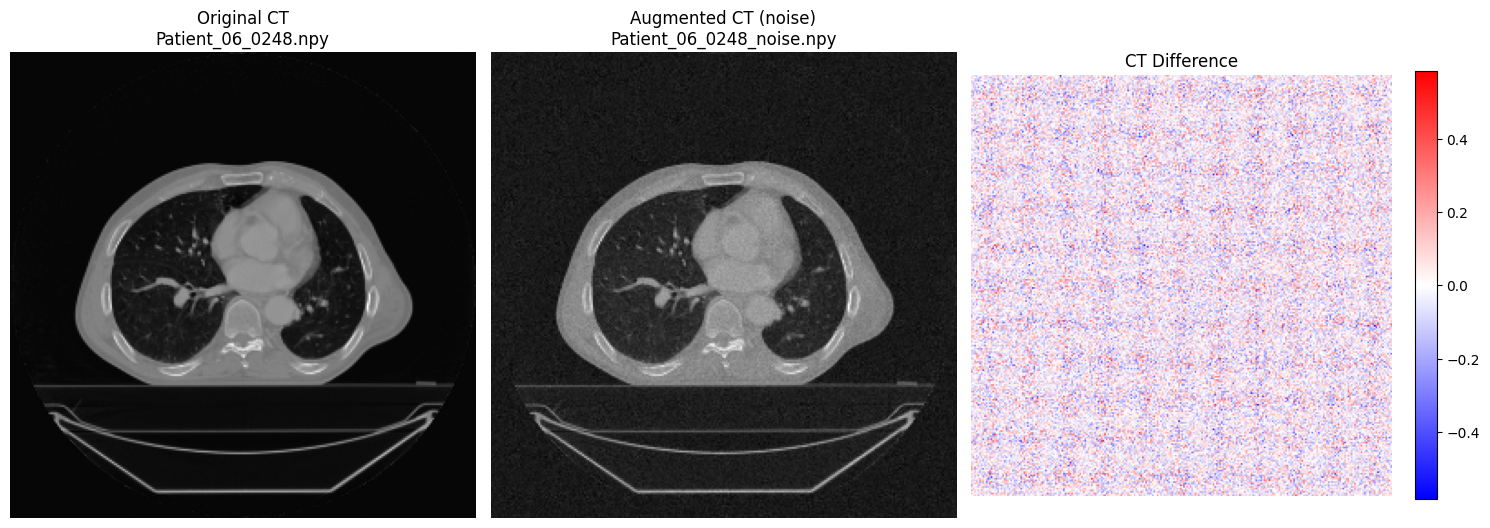


Total abs CT difference: 6173.77, max diff: 0.5842


In [15]:
orig_img = np.load(original_path)
aug_img = np.load(example_aug_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 10))

axes[0].imshow(orig_img, cmap='gray')
axes[0].set_title(f"Original CT\n{original_path.name}")
axes[0].axis('off')

axes[1].imshow(aug_img, cmap='gray')
axes[1].set_title(f"Augmented CT ({tag})\n{example_aug_path.name}")
axes[1].axis('off')

diff = aug_img - orig_img
im1 = axes[2].imshow(diff, cmap='bwr', vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
axes[2].set_title("CT Difference")
axes[2].axis('off')
plt.colorbar(im1, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print(f"\nTotal abs CT difference: {np.abs(diff).sum():.2f}, max diff: {np.abs(diff).max():.4f}")

### Visualize patient 20

In [ ]:
base_dir = Path("data/SEGTHOR_gaussian/train")
img_dir = base_dir / "img"
gt_dir = base_dir / "gt"

patient_id = "Patient_20"

# Find which augmented versions actually exist for this patient
augmented_files = sorted(img_dir.glob(f"{patient_id}_*_*.npy"))  # anything with an extra tag after the slice index
print(f"Found {len(augmented_files)} augmented slices for {patient_id}")
for f in augmented_files[:10]:
    print(f.name)

if not augmented_files:
    raise FileNotFoundError(f"No augmented slices found for {patient_id} — check your naming pattern or that generation actually ran.")

# Pick one augmented slice and find its matching original
example_aug_path = augmented_files[len(augmented_files) // 2]  # grab one from the middle

# Extract the slice index and tag from the filename
# e.g. "Patient_07_0055_elastic_noise.npy" -> stem parts
stem = example_aug_path.stem  # "Patient_02_0055_elastic_noise"
parts = stem.split("_")
# id_ is "Patient_07" (first two parts), idz is parts[2], tag is whatever comes after
idz_str = parts[2]
tag = "_".join(parts[3:])

original_path = img_dir / f"{patient_id}_{idz_str}.npy"
original_gt_path = gt_dir / f"{patient_id}_{idz_str}.png"
aug_gt_path = gt_dir / f"{stem}.png"

print(f"\nComparing:")
print(f"  Original: {original_path.name}")
print(f"  Augmented ({tag}): {example_aug_path.name}")

assert original_path.exists(), f"Missing original slice: {original_path}"


Found 514 augmented slices for Patient_20
Patient_20_0000_noise.npy
Patient_20_0001_noise.npy
Patient_20_0002_noise.npy
Patient_20_0003_noise.npy
Patient_20_0004_noise.npy
Patient_20_0005_noise.npy
Patient_20_0006_noise.npy
Patient_20_0007_noise.npy
Patient_20_0008_noise.npy
Patient_20_0009_noise.npy

Comparing:
  Original: Patient_20_0257.npy
  Augmented (noise): Patient_20_0257_noise.npy


### Scaling the difference map with vmin and vmax

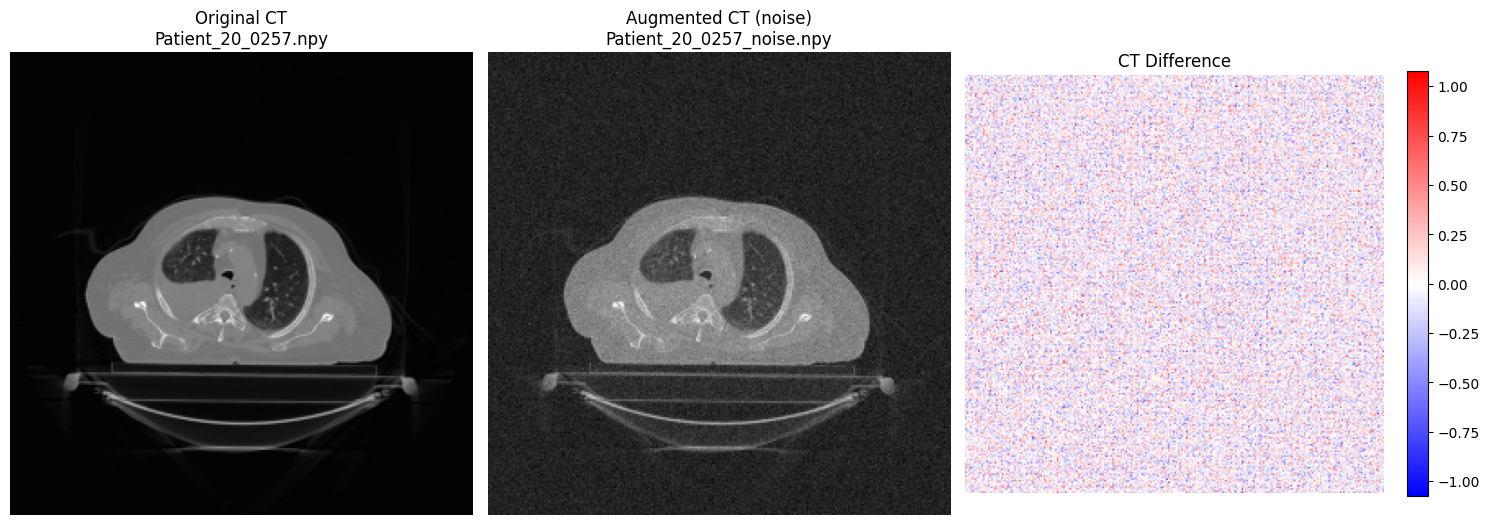


Total abs CT difference: 9801.37, max diff: 1.0777


In [18]:
orig_img = np.load(original_path)
aug_img = np.load(example_aug_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 10))

axes[0].imshow(orig_img, cmap='gray')
axes[0].set_title(f"Original CT\n{original_path.name}")
axes[0].axis('off')

axes[1].imshow(aug_img, cmap='gray')
axes[1].set_title(f"Augmented CT ({tag})\n{example_aug_path.name}")
axes[1].axis('off')

diff = aug_img - orig_img
im1 = axes[2].imshow(diff, cmap='bwr', vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
axes[2].set_title("CT Difference")
axes[2].axis('off')
plt.colorbar(im1, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()

print(f"\nTotal abs CT difference: {np.abs(diff).sum():.2f}, max diff: {np.abs(diff).max():.4f}")